# Urbane Luftverschmutzung: Baseline-Modell (Meilenstein 2)

Aufbauend auf der EDA (Meilenstein 1) bauen wir hier die **Baseline**: das
einfachste Modell, das funktionieren könnte. Es liefert einen Score, den
spätere Modelle schlagen müssen.

## Definition der Baseline

- **Nutzen des Produkts:** Tägliche PM2.5-Werte für Orte ohne Messstation
  schätzen, damit Behörden früher warnen und gezielter handeln können.
- **Vorhersage:** Mittleres tägliches PM2.5 (`target`, µg/m³) pro Ort und Tag.
- **Metrik:** RMSE (Vorgabe von Zindi). Große Fehler bei Belastungsspitzen
  werden stark bestraft. Zusätzlich berichten wir MAE und R² zur Einordnung.
- **Validierung:** `GroupKFold` nach `Place_ID`. Train und Test enthalten
  ungleiche Orte (siehe EDA), ein zufälliger Split wäre zu optimistisch.
- **Baseline-Modelle:**
  1. Globaler Mittelwert des Targets (dümmste mögliche Vorhersage).
  2. Mittelwert pro Datum (nutzt nur das gemeinsame Tageswetter-Signal).
  3. Erstes echtes Modell: Gradient Boosting auf Wetter-, Satelliten- und
     Datumsfeatures, mit minimaler Aufbereitung.

In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_DIR = Path("data")

## 1. Daten laden und Features festlegen

In [ ]:
train = pd.read_csv(DATA_DIR / "Train.csv", parse_dates=["Date"])
test = pd.read_csv(DATA_DIR / "Test.csv", parse_dates=["Date"])

target = "target"
meta_cols = ["Place_ID X Date", "Date", "Place_ID"]
# target_min/max/variance/count gibt es nur in Train (Leakage) und sind
# nicht in dieser Liste, da sie nicht in Test vorkommen.


# Datumsfeatures (Train und Test decken denselben Zeitraum ab)
for df in (train, test):
    df["dayofyear"] = df["Date"].dt.day_of_year
    df["weekday"] = df["Date"].dt.day_of_week
    df["wind_speed"] = np.sqrt(df["u_component_of_wind_10m_above_ground"]**2
    + df["v_component_of_wind_10m_above_ground"]**2)

features = features = [
    "wind_speed",
    "L3_HCHO_tropospheric_HCHO_column_number_density",
    "L3_CO_CO_column_number_density",
    "L3_NO2_NO2_column_number_density",
    "L3_SO2_absorbing_aerosol_index",
    "L3_CLOUD_cloud_fraction",
    "dayofyear",
    "weekday",
    ]
X, y = train[features], train[target]
groups = train["Place_ID"]
print(f"{len(features)} Features, {len(train)} Trainingszeilen, "
      f"{groups.nunique()} Orte")

76 Features, 30557 Trainingszeilen, 340 Orte


## 2. Validierungs-Setup

Wir nutzen 5-fach `GroupKFold`: Alle Zeilen eines Ortes liegen immer
vollständig im Training **oder** in der Validierung. So messen wir, wie gut das
Modell auf unbekannte Orte verallgemeinert, genau wie später im Test.

In [27]:
cv = GroupKFold(n_splits=5)
folds = list(cv.split(X, y, groups))


def evaluate(name, fit_predict):
    """Führt die Cross-Validation aus und gibt Metriken als Zeile zurück."""
    oof = np.zeros(len(train))
    for tr_idx, va_idx in folds:
        oof[va_idx] = fit_predict(tr_idx, va_idx)
    rmse = np.sqrt(mean_squared_error(y, oof))
    fold_rmse = [np.sqrt(mean_squared_error(y.iloc[va], oof[va]))
                 for _, va in folds]
    return oof, {"Modell": name, "RMSE": rmse,
                 "RMSE Fold-Std": np.std(fold_rmse),
                 "MAE": mean_absolute_error(y, oof),
                 "R²": r2_score(y, oof)}


results, oofs = [], {}

## 3. Baseline 1: globaler Mittelwert

Jeder Ort und jeder Tag bekommt den Mittelwert des Trainingstargets.

In [28]:
def global_mean(tr_idx, va_idx):
    return np.full(len(va_idx), y.iloc[tr_idx].mean())


oofs["Globaler Mittelwert"], row = evaluate("Globaler Mittelwert", global_mean)
results.append(row)
print(f"RMSE: {row['RMSE']:.2f}")

RMSE: 47.11


## 4. Baseline 2: Mittelwert pro Datum

Für jedes Datum nutzen wir den mittleren Target-Wert der **Trainings-Orte** an
diesem Tag. Das fängt tagesweite Schwankungen ein (gemeinsames Wetter), sagt
aber nichts über Unterschiede zwischen Orten.

In [29]:
def date_mean(tr_idx, va_idx):
    means = y.iloc[tr_idx].groupby(train["Date"].iloc[tr_idx]).mean()
    pred = train["Date"].iloc[va_idx].map(means)
    return pred.fillna(y.iloc[tr_idx].mean()).to_numpy()


oofs["Mittelwert pro Datum"], row = evaluate("Mittelwert pro Datum", date_mean)
results.append(row)
print(f"RMSE: {row['RMSE']:.2f}")

RMSE: 46.65


## 5. Erstes Modell A: Ridge-Regression (linear)

Minimale Aufbereitung: fehlende Werte mit dem Median füllen, Features
standardisieren. Dient als linearer Vergleich.

In [30]:
def ridge(tr_idx, va_idx):
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          Ridge(alpha=10.0))
    model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
    return model.predict(X.iloc[va_idx])


oofs["Ridge"], row = evaluate("Ridge", ridge)
results.append(row)
print(f"RMSE: {row['RMSE']:.2f}")

RMSE: 37.96


## 6. Erstes Modell B: Gradient Boosting

`HistGradientBoostingRegressor` verarbeitet `NaN` direkt, braucht also keine
Imputation. Wir verwenden die Standardparameter (Tuning folgt in Meilenstein 3).

In [31]:
def hgb(tr_idx, va_idx):
    model = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
    model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
    return model.predict(X.iloc[va_idx])


oofs["Gradient Boosting"], row = evaluate("Gradient Boosting", hgb)
results.append(row)
print(f"RMSE: {row['RMSE']:.2f}")

RMSE: 33.39


## 7. Vergleich der Baselines

In [32]:
res = pd.DataFrame(results).set_index("Modell").round(2)
res

,RMSE,RMSE Fold-Std,MAE,R²
Modell,,,,
Globaler Mittelwert,47.11,5.83,35.03,-0.01
Mittelwert pro Datum,46.65,5.62,34.95,0.01
Ridge,37.96,4.53,27.34,0.34
Gradient Boosting,33.39,3.49,23.06,0.49


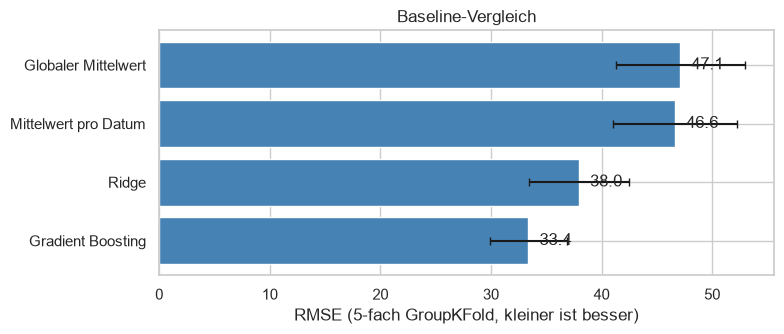

In [33]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(res.index[::-1], res["RMSE"][::-1], color="steelblue",
        xerr=res["RMSE Fold-Std"][::-1], capsize=3)
for i, v in enumerate(res["RMSE"][::-1]):
    ax.text(v + 1, i, f"{v:.1f}", va="center")
ax.set_xlabel("RMSE (5-fach GroupKFold, kleiner ist besser)")
ax.set_title("Baseline-Vergleich")
plt.tight_layout()
plt.show()

## 8. Fehleranalyse (erster Blick)

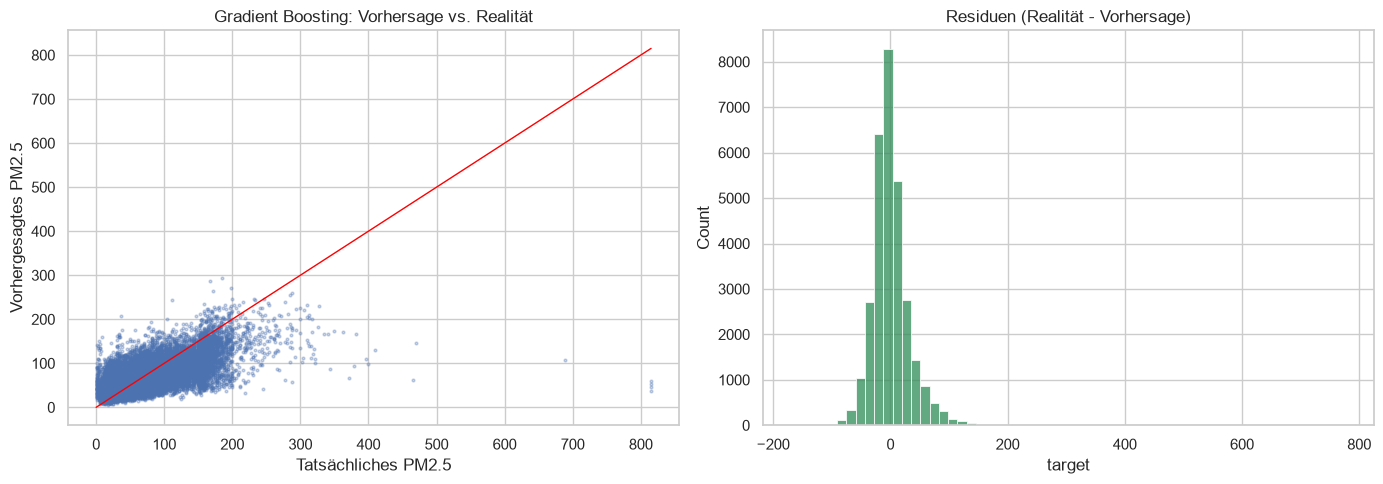

In [34]:
best = "Gradient Boosting"
pred = oofs[best]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y, pred, s=4, alpha=0.3)
lim = [0, max(y.max(), pred.max())]
axes[0].plot(lim, lim, color="red", lw=1)
axes[0].set_xlabel("Tatsächliches PM2.5")
axes[0].set_ylabel("Vorhergesagtes PM2.5")
axes[0].set_title(f"{best}: Vorhersage vs. Realität")

resid = y - pred
sns.histplot(resid, bins=60, ax=axes[1], color="seagreen")
axes[1].set_title("Residuen (Realität - Vorhersage)")
plt.tight_layout()
plt.show()

In [35]:
# Wo entsteht der Fehler? Nach Höhe des tatsächlichen Targets
bins = pd.cut(y, [0, 25, 50, 100, 150, 200, 1000])
err = pd.DataFrame({"bin": bins, "se": resid ** 2, "ae": resid.abs()})
by_bin = err.groupby("bin", observed=True).agg(
    Zeilen=("se", "size"), MAE=("ae", "mean"), SE_Summe=("se", "sum"))
by_bin["Anteil am Gesamtfehler"] = (by_bin["SE_Summe"]
                                    / by_bin["SE_Summe"].sum()).round(3)
by_bin.drop(columns="SE_Summe").round(1)

,Zeilen,MAE,Anteil am Gesamtfehler
bin,,,
"(0, 25]",7718,20.7,0.2
"(25, 50]",7635,16.2,0.1
"(50, 100]",10265,18.1,0.2
"(100, 150]",2627,36.1,0.1
"(150, 200]",2056,53.9,0.2
"(200, 1000]",256,114.1,0.2


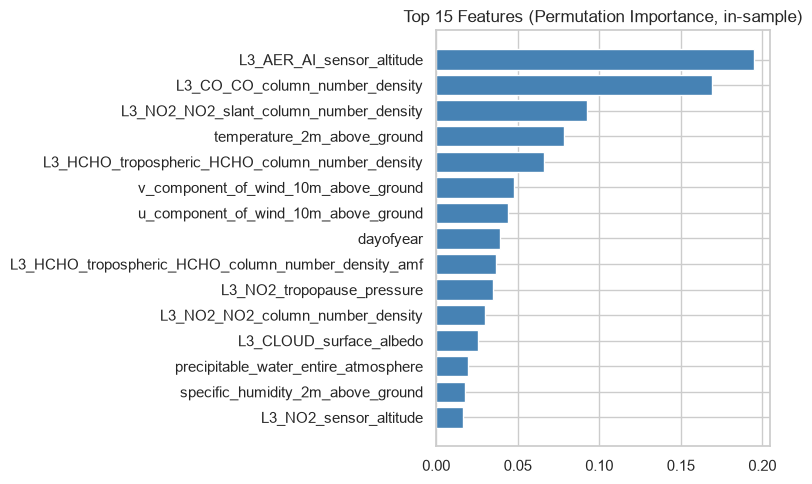

In [36]:
# Wichtigste Features per Permutation Importance (auf Stichprobe, in-sample)
model = HistGradientBoostingRegressor(random_state=RANDOM_STATE).fit(X, y)
sub = X.sample(3000, random_state=RANDOM_STATE)
imp = permutation_importance(model, sub, y.loc[sub.index], n_repeats=3,
                             random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(imp.importances_mean, index=features).sort_values(
    ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index[::-1], imp.values[::-1], color="steelblue")
ax.set_title("Top 15 Features (Permutation Importance, in-sample)")
plt.tight_layout()
plt.show()

## 9. Ergebnis und nächste Schritte

**Baseline-Score (RMSE, 5-fach GroupKFold):**

| Modell | RMSE |
| --- | --- |
| Globaler Mittelwert | 47,1 |
| Mittelwert pro Datum | 46,7 |
| Ridge | 38,0 |
| Gradient Boosting (Standardparameter) | **33,4** |

Der globale Mittelwert entspricht ungefähr der Standardabweichung des Targets
und ist die untere Messlatte. Unser erstes echtes Modell (Gradient Boosting,
RMSE 33,4, R² 0,49) ist der Score, den Meilenstein 3 schlagen muss.

**Beobachtungen**

- Der Mittelwert pro Datum bringt kaum Verbesserung: Die Unterschiede zwischen
  den Orten (EDA: etwa 62 % der Varianz) sind wichtiger als die Tagesschwankung.
- Gradient Boosting auf den Rohfeatures senkt den RMSE um etwa 29 % gegenüber
  dem globalen Mittelwert und schlägt auch Ridge (nichtlineare
  Zusammenhänge helfen), erklärt aber nur etwa die Hälfte der Varianz.
- Der mittlere Fehler (MAE) steigt mit der Höhe des tatsächlichen Werts stark
  an (etwa 20 µg/m³ bei Werten bis 25, über 100 µg/m³ bei Werten über 200). Die
  wenigen Spitzenwerte über 200 (256 Zeilen) verursachen rund ein Fünftel des
  gesamten quadratischen Fehlers, wie in der EDA vermutet.

**Plan für Meilenstein 3 (Modell mit Fehleranalyse)**

- Mindestens drei Algorithmen vergleichen (z. B. Random Forest, Gradient
  Boosting, LightGBM/XGBoost), inklusive Cross-Validation und
  Hyperparameter-Tuning.
- Feature Engineering: nahezu doppelte Winkelspalten reduzieren,
  Aggregate der Features pro Datum und pro Ort (aus Test-Features ohne Target),
  Interaktionen aus Wetter und Schadstoffen.
- `log1p(target)` und den Umgang mit Spitzen (Kappen, gewichtete Loss)
  prüfen.
- Fehleranalyse nach Orten und Zeit: Welche Orte werden systematisch
  unter- oder überschätzt?